In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/yasserh/bike-sharing-dataset/day.csv


In [2]:
df = pd.read_csv("/kaggle/input/datasets/yasserh/bike-sharing-dataset/day.csv")
df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,01-01-2018,1,0,1,0,6,0,2,14.110847,18.18125,80.5833,10.749882,331,654,985
1,2,02-01-2018,1,0,1,0,0,0,2,14.902598,17.68695,69.6087,16.652113,131,670,801
2,3,03-01-2018,1,0,1,0,1,1,1,8.050924,9.47025,43.7273,16.636703,120,1229,1349
3,4,04-01-2018,1,0,1,0,2,1,1,8.200000,10.60610,59.0435,10.739832,108,1454,1562
4,5,05-01-2018,1,0,1,0,3,1,1,9.305237,11.46350,43.6957,12.522300,82,1518,1600
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,726,27-12-2019,1,1,12,0,4,1,2,10.420847,11.33210,65.2917,23.458911,247,1867,2114
726,727,28-12-2019,1,1,12,0,5,1,2,10.386653,12.75230,59.0000,10.416557,644,2451,3095
727,728,29-12-2019,1,1,12,0,6,0,2,10.386653,12.12000,75.2917,8.333661,159,1182,1341
728,729,30-12-2019,1,1,12,0,0,0,1,10.489153,11.58500,48.3333,23.500518,364,1432,1796


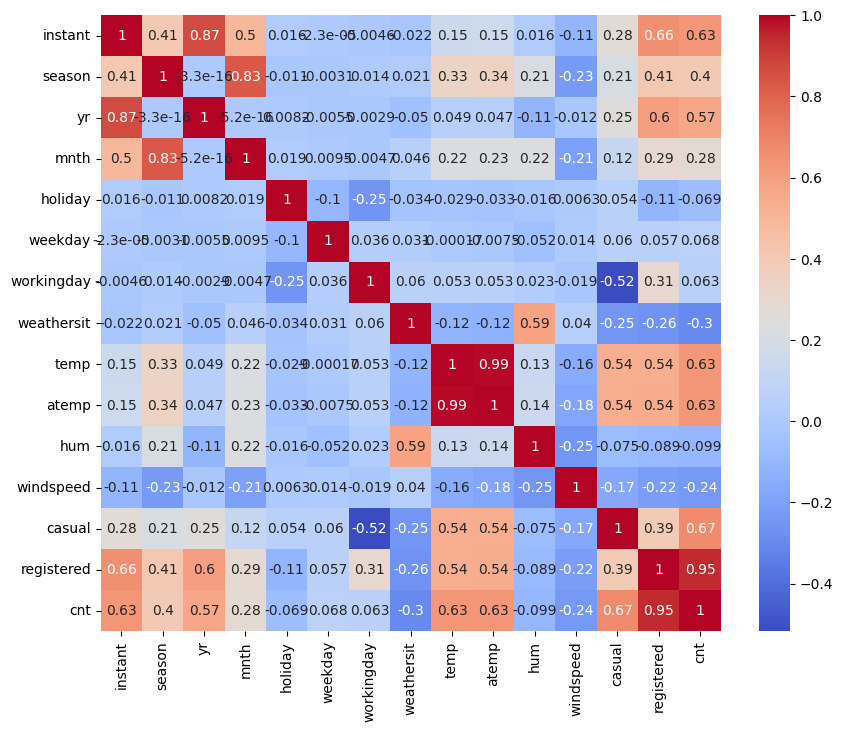

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.show()

In [4]:
x = df[["registered", "casual", "temp"]]
y = df["cnt"]
x,y

(     registered  casual       temp
 0           654     331  14.110847
 1           670     131  14.902598
 2          1229     120   8.050924
 3          1454     108   8.200000
 4          1518      82   9.305237
 ..          ...     ...        ...
 725        1867     247  10.420847
 726        2451     644  10.386653
 727        1182     159  10.386653
 728        1432     364  10.489153
 729        2290     439   8.849153
 
 [730 rows x 3 columns],
 0       985
 1       801
 2      1349
 3      1562
 4      1600
        ... 
 725    2114
 726    3095
 727    1341
 728    1796
 729    2729
 Name: cnt, Length: 730, dtype: int64)

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
import cupy as cp
print(cp.__version__)
print(cp.cuda.runtime.getDeviceCount())

14.0.1
2


In [6]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,random_state=42, test_size=0.2)

In [7]:
def mse(y):
    return sum((y.mean()-y)**2)

In [8]:
def split_score(x,y,feature,treshold):
    value = x[:,feature]
    left = value[None,:]<=treshold[:,None]

    nleft = left.sum(axis=1)
    nright = x.shape[0]-nleft

    y2 = y**2

    sumleft = (left*y[None,:]).sum(axis=1)
    sum2left = (left*y2[None, :]).sum(axis=1)

    sumtotal = sumleft.sum()
    sum2total = sum2left.sum()

    sumright = sumtotal-sumleft
    sum2right = sum2total-sum2left

    mse = cp.full(treshold.shape, cp.inf,dtype=cp.float32)

    valid = (nleft>0) & (nright>0)

    sseleft = sum2left[valid] - (sumleft[valid]**2)/nleft[valid]
    sseright = sum2right[valid] - (sumright[valid]**2)/nright[valid]

    mse[valid] = (sseleft+sseright)/x.shape[0]

    return mse

In [9]:
xgpu = cp.asarray(xtrain.values,dtype=cp.float32)
ygpu = cp.asarray(ytrain.values, dtype = cp.float32)
treshold = cp.unique(xgpu[:,2])
split_score(xgpu,ygpu, 2,treshold)

array([-5.75314657e+11, -5.76306938e+11, -5.77301185e+11, -5.78300740e+11,
       -5.79301868e+11, -5.80306993e+11, -5.81315265e+11, -5.82325699e+11,
       -5.84361312e+11, -5.85381315e+11, -5.86408133e+11, -5.87438031e+11,
       -5.88472451e+11, -5.89508968e+11, -5.90546665e+11, -5.91590851e+11,
       -5.92637788e+11, -5.94737299e+11, -5.95799048e+11, -5.97929230e+11,
       -5.98998909e+11, -6.00072782e+11, -6.01151635e+11, -6.02233045e+11,
       -6.03318190e+11, -6.04404384e+11, -6.05498900e+11, -6.06598726e+11,
       -6.08803684e+11, -6.09910587e+11, -6.11024044e+11, -6.12140450e+11,
       -6.14382567e+11, -6.15511032e+11, -6.17778971e+11, -6.18921132e+11,
       -6.20069323e+11, -6.21220987e+11, -6.23537684e+11, -6.24696361e+11,
       -6.27034685e+11, -6.29389263e+11, -6.30572319e+11, -6.31761863e+11,
       -6.32957043e+11, -6.34158645e+11, -6.36558639e+11, -6.37767713e+11,
       -6.38985110e+11, -6.41431503e+11, -6.43893166e+11, -6.47615611e+11,
       -6.48869970e+11, -

In [10]:
def best_split(x,y):
    best = None
    bestscr = float("inf")
    xgpu = cp.asarray(x.values, dtype=cp.float32)
    ygpu = cp.asarray(y.values, dtype=cp.float32)

    for feature in x:
        feature_idx = x.columns.get_loc(feature)

        treshold = cp.unique(xgpu[:,feature_idx])[:-1]
        if treshold.size==0:
            continue
        scores = split_score(xgpu, ygpu, feature_idx, treshold)
        bestidx = cp.argmin(scores)
        best_treshold = treshold[bestidx]
        best_treshold = float(best_treshold.get())
        best_scr = scores[bestidx]
        left = x[feature]<=best_treshold
        right = ~left

        if left is None or right is None:
            continue
        if best_scr<bestscr:
            bestscr= best_scr
            best = {
                "feature": feature,
                "treshold": best_treshold,
                "left": (x[left],y[left]),
                "right": (x[right], y[right])
            }
    return best

In [11]:
print(best_split(xtrain,ytrain))

{'feature': 'casual', 'treshold': 3252.0, 'left': (     registered  casual       temp
247        2115    1236  27.606653
335        3672     268  12.880847
702        6055     551  19.509153
440        4681    3155  21.080847
136        3445     678  23.028347
..          ...     ...        ...
71         1435     982  15.758268
106        2186    1558  18.723347
270        3427     480  26.035000
435        4460     838  19.133347
102        1953     209  16.912500

[583 rows x 3 columns], 247    3351
335    3940
702    6606
440    7836
136    4123
       ... 
71     2417
106    3744
270    3907
435    5298
102    2162
Name: cnt, Length: 583, dtype: int64), 'right': (     registered  casual  temp
503        4884    3410  24.6, 503    8294
Name: cnt, dtype: int64)}
